# 🚨 Global Solution 2026.2
## Segurança pública inteligente em São Paulo: classificação de ocorrências com MLP

**Matéria:** Aprendizado Profundo com Redes Neurais Convolucionais

**Turma:** 2CCPA

**Integrantes:**

- Natalia Heloisa Rocha de Alcântara Bezerra – RM 568570

- Raissa Marinho de Jesus Viana – RM 568301


**Tema:** classificar uma ocorrência de subtração de celular como **roubo** ou **furto** usando uma rede neural MLP.
> A MLP não prevê se um crime vai acontecer. Ela só identifica o tipo de uma ocorrência já registrada.

**Fonte dos dados:** SSP-SP, base *Celulares Subtraídos 2026*
🔗 https://www.ssp.sp.gov.br/estatistica/consultas

**Período dos dados:** 01/01/2026 a 30/09/2026 (data de registro do BO), apenas fatos ocorridos na capital (CIDADE = S.PAULO)

In [1]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Separação dos dados, codificação e métricas
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

# Rede neural (MLP)
from tensorflow import keras
from tensorflow.keras import layers

# Gráficos
import matplotlib.pyplot as plt

# Salvar o encoder
import joblib

## 1. Carregando e conhecendo os dados

In [2]:
arquivo = "/content/CelularesSubtraidos_2026.xlsx"
abas = pd.ExcelFile(arquivo).sheet_names
print(abas)

['METODOLOGIA', 'DICIONARIO DE DADOS', 'CELULAR_2026']


In [3]:
df = pd.read_excel(arquivo, sheet_name="CELULAR_2026")

print("Linhas e colunas:", df.shape)
print(df.columns.tolist())
df.head()

Linhas e colunas: (256076, 55)
['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CIA', 'COD IBGE']


,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,...,QUANTIDADE_OBJETO,MARCA_OBJETO,FLAG_BLOQUEIO,FLAG_DESBLOQUEIO,MES_REGISTRO_BO,ANO_REGISTRO_BO,CMD,BTL,CIA,COD IBGE
0,10101,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,S.PAULO,2025,TB7197,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,20230,DECAP,DEL.SEC.5º LESTE,30º D.P. TATUAPE,S.PAULO,2026,AA0506,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,NaN,NaN,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA1535,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
3,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA1574,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
4,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA2028,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308


## 2. Explorando: capital, rótulo e período

In [4]:
# Quais cidades aparecem como local do fato?
print(df["CIDADE"].value_counts().head(10))

# Tipos de ocorrência (aqui deve ter roubo e furto)
print(df["RUBRICA"].value_counts())

# Período: primeira e última data dos fatos
datas = pd.to_datetime(df["DATA_OCORRENCIA_BO"], errors="coerce")
print("Período:", datas.min(), "até", datas.max())

CIDADE
S.PAULO                150990
GUARULHOS                7090
CAMPINAS                 5577
S.ANDRE                  4967
OSASCO                   4823
S.BERNARDO DO CAMPO      3834
PRAIA GRANDE             2801
SOROCABA                 2408
RIBEIRAO PRETO           2334
ITAQUAQUECETUBA          2117
Name: count, dtype: int64
RUBRICA
Furto (art. 155)                                                                   117027
Roubo (art. 157)                                                                    82559
Perda/Extravio                                                                      38104
Localização/Apreensão e Entrega de veículo                                           3218
Outros não criminal                                                                  2485
                                                                                    ...  
Abalroamento                                                                            1
Praticar ato de abuso a anima

### 📝 O que descobrimos
- A base tem **256.076 linhas e 55 colunas**. Em `CIDADE` (local do fato), **S.PAULO** aparece 150.990 vezes. Usamos `CIDADE` e não `NOME_MUNICIPIO`, porque este é o município da delegacia, não do fato.
- A coluna `RUBRICA` diz o tipo da ocorrência. As duas classes do problema são **Furto (art. 155)**, com 117.027 registros, e **Roubo (art. 157)**, com 82.559. As outras rubricas (perda/extravio etc.) não fazem parte do problema.
- Alguns fatos são de anos antigos (2006) e só foram registrados em 2026, então o período será definido pela **data de registro do BO**.

## 3. Filtrando a capital e criando o rótulo

In [5]:
# 1) Fica só com fatos ocorridos na capital (CIDADE = local do fato)
df_sp = df[df["CIDADE"] == "S.PAULO"].copy()

# 2) Fica só com roubo e furto (o resto não interessa pro problema)
df_sp = df_sp[df_sp["RUBRICA"].isin(["Furto (art. 155)", "Roubo (art. 157)"])].copy()

# 3) Cria o rótulo: 1 = roubo, 0 = furto
df_sp["ROUBO"] = (df_sp["RUBRICA"] == "Roubo (art. 157)").astype(int)

print("Registros da capital (roubo + furto):", df_sp.shape[0])
print(df_sp["ROUBO"].value_counts())
print(df_sp["ROUBO"].value_counts(normalize=True).round(3))

# Período pela data de registro do BO
registro = pd.to_datetime(df_sp["DATAHORA_REGISTRO_BO"], errors="coerce")
print("Período (registro do BO):", registro.min().date(), "até", registro.max().date())

Registros da capital (roubo + furto): 126567
ROUBO
0    77003
1    49564
Name: count, dtype: int64
ROUBO
0    0.608
1    0.392
Name: proportion, dtype: float64
Período (registro do BO): 2026-01-01 até 2026-09-30


### 📝 O que fizemos
Filtramos só a capital e só roubo/furto, e criamos o rótulo `ROUBO` (1 = roubo, 0 = furto).

- **126.567 registros**: 77.003 furtos (60,8%) e 49.564 roubos (39,2%).
- **Período:** 01/01/2026 a 30/09/2026 (data de registro do BO).
- As classes **não estão perfeitamente balanceadas**, mas a diferença é moderada. Por isso, além da acurácia, vamos avaliar **precision, recall e F1-score**.

## 4. Limpeza e escolha dos atributos

In [6]:
# Um BO pode ter vários itens (ex: 2 celulares), o que gera linhas repetidas.
# Fica com 1 linha por boletim pra não contar o mesmo caso duas vezes
antes = df_sp.shape[0]
df_sp = df_sp.drop_duplicates(subset=["ANO_BO", "NUM_BO", "NOME_DELEGACIA"])
print(f"Duplicados removidos: {antes - df_sp.shape[0]}")
print("Registros agora:", df_sp.shape[0])

# Atributos candidatos: quantos valores ausentes cada um tem?
candidatos = ["BAIRRO", "DESCR_PERIODO", "HORA_OCORRENCIA", "DATA_OCORRENCIA_BO",
              "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL", "DESCR_TIPO_OBJETO"]
print(df_sp[candidatos].isna().mean().round(3))

# Quantos valores diferentes cada um tem?
print(df_sp[candidatos].nunique())

Duplicados removidos: 14375
Registros agora: 112192
BAIRRO                0.002
DESCR_PERIODO         0.588
HORA_OCORRENCIA       0.412
DATA_OCORRENCIA_BO    0.000
DESCR_TIPOLOCAL       0.000
DESCR_SUBTIPOLOCAL    0.000
DESCR_TIPO_OBJETO     0.000
dtype: float64
BAIRRO                1807
DESCR_PERIODO            5
HORA_OCORRENCIA       6600
DATA_OCORRENCIA_BO     620
DESCR_TIPOLOCAL         28
DESCR_SUBTIPOLOCAL     184
DESCR_TIPO_OBJETO        1
dtype: int64


### 📝 O que fizemos
- Um mesmo BO pode ter vários itens (ex.: dois celulares), gerando linhas repetidas. Removemos **14.375 duplicados** e ficamos com **112.192 boletins**, 1 linha por caso.
- `DESCR_TIPO_OBJETO` tem 1 único valor (tudo é celular), então não ajuda o modelo. **Descartada.**
- `BAIRRO` tem 1.807 valores diferentes. Vamos manter só os mais frequentes para a rede não ficar enorme.
- `DESCR_PERIODO` (58,8% ausente) e `HORA_OCORRENCIA` (41,2% ausente) se completam. Vamos juntar os dois numa coluna única de período do dia.
- Ficaram de fora `DESCR_CONDUTA`, `DESDOBRAMENTO` e `CIRCUNSTANCIA`, porque podem **revelar a resposta** (data leakage).

In [7]:
# Valores de DESCR_PERIODO
print(df_sp["DESCR_PERIODO"].value_counts(dropna=False))

# HORA e PERIODO se completam? (a gente espera 0 nos dois primeiros)
print("Sem hora e sem período:", (df_sp["HORA_OCORRENCIA"].isna() & df_sp["DESCR_PERIODO"].isna()).sum())
print("Com hora e com período:", (df_sp["HORA_OCORRENCIA"].notna() & df_sp["DESCR_PERIODO"].notna()).sum())

# Como a hora vem escrita?
print(df_sp["HORA_OCORRENCIA"].dropna().head())

# Tipos de local e cobertura dos bairros mais frequentes
print(df_sp["DESCR_TIPOLOCAL"].value_counts().head(10))
print("Os 100 bairros mais comuns cobrem:", df_sp["BAIRRO"].value_counts(normalize=True).head(100).sum().round(3))

DESCR_PERIODO
NaN                65923
A noite            13839
A tarde            13301
Pela manhã         11657
De madrugada        7096
Em hora incerta      376
Name: count, dtype: int64
Sem hora e sem período: 0
Com hora e com período: 0
0     15:00:00
1     21:30:00
4     18:15:00
5     18:50:00
11    00:45:00
Name: HORA_OCORRENCIA, dtype: object
DESCR_TIPOLOCAL
Via Pública               98472
Terminal/Estação           6163
Outros                     3574
Residência                  843
Comércio e Serviços         448
Restaurante e Afins         416
Rodovia/Estrada             389
Lazer e Recreação           375
Estacionamento/Garagem      274
Shopping Center             229
Name: count, dtype: int64
Os 100 bairros mais comuns cobrem: 0.738


### 📝 Confirmando a junção
Conferimos que nenhum registro tem hora e período ao mesmo tempo, e nenhum está sem os dois. Ou seja, um **completa o outro** e dá pra juntar sem perder dados.
- `DESCR_TIPOLOCAL` é dominada por **Via Pública** (98.472), então vamos manter só os 6 tipos mais comuns e agrupar o resto em "Outros".
- Os **100 bairros mais comuns cobrem 73,8%** dos casos. O restante vira "OUTROS".

## 5. Montando os atributos

In [8]:
# --- PERIODO: junta DESCR_PERIODO com a hora exata ---
# Pega só as 2 primeiras letras da hora ("15:00:00" -> 15)
hora = pd.to_numeric(df_sp["HORA_OCORRENCIA"].astype(str).str[:2], errors="coerce")

# Transforma a hora em período do dia
periodo_da_hora = pd.cut(hora, bins=[-1, 5, 11, 17, 23],
                         labels=["De madrugada", "Pela manhã", "A tarde", "A noite"])

# Onde DESCR_PERIODO está vazio, usa o período calculado pela hora
df_sp["PERIODO"] = df_sp["DESCR_PERIODO"].fillna(periodo_da_hora.astype(object))

# Tira "Em hora incerta" (não dá pra saber o período)
df_sp = df_sp[df_sp["PERIODO"] != "Em hora incerta"].copy()

# --- DIA_SEMANA: a partir da data do fato ---
datas = pd.to_datetime(df_sp["DATA_OCORRENCIA_BO"], errors="coerce")
nomes_dias = {0: "segunda", 1: "terça", 2: "quarta", 3: "quinta",
              4: "sexta", 5: "sábado", 6: "domingo"}
df_sp["DIA_SEMANA"] = datas.dt.dayofweek.map(nomes_dias)

# --- BAIRRO: mantém os 100 mais comuns, o resto vira OUTROS ---
top_bairros = df_sp["BAIRRO"].value_counts().head(100).index
df_sp["BAIRRO_GRUPO"] = df_sp["BAIRRO"].where(df_sp["BAIRRO"].isin(top_bairros), "OUTROS")

# --- TIPO_LOCAL: mantém os 6 mais comuns, o resto vira Outros ---
top_locais = df_sp["DESCR_TIPOLOCAL"].value_counts().head(6).index
df_sp["TIPO_LOCAL"] = df_sp["DESCR_TIPOLOCAL"].where(df_sp["DESCR_TIPOLOCAL"].isin(top_locais), "Outros")

# --- Tabela final só com o que a MLP vai usar + o rótulo ---
df_modelo = df_sp[["BAIRRO_GRUPO", "DIA_SEMANA", "PERIODO", "TIPO_LOCAL", "ROUBO"]].dropna()

print("Registros finais:", df_modelo.shape[0])
print(df_modelo["ROUBO"].value_counts(normalize=True).round(3))
df_modelo.head()

Registros finais: 111816
ROUBO
0    0.649
1    0.351
Name: proportion, dtype: float64


,BAIRRO_GRUPO,DIA_SEMANA,PERIODO,TIPO_LOCAL,ROUBO
0,LIBERDADE,domingo,A tarde,Outros,0
1,LIBERDADE,quarta,A noite,Via Pública,1
2,SE,terça,A tarde,Via Pública,0
3,SE,terça,A tarde,Via Pública,0
4,SE,terça,A noite,Via Pública,1


### 📝 Atributos finais
Montamos a tabela que a MLP vai usar, com **4 atributos de entrada** e o rótulo:

| Atributo | Como foi feito |
|---|---|
| `BAIRRO_GRUPO` | 100 bairros mais frequentes; os demais viram "OUTROS" |
| `DIA_SEMANA` | extraído da data do fato |
| `PERIODO` | junção de `DESCR_PERIODO` com a hora exata (madrugada, manhã, tarde, noite) |
| `TIPO_LOCAL` | 6 tipos mais frequentes; os demais viram "Outros" |

- **111.816 registros** finais, sendo 64,9% furto e 35,1% roubo. A proporção mudou em relação à anterior porque os duplicados removidos eram mais de roubo (um mesmo BO costuma ter vários itens).
- O rótulo `ROUBO` **não está entre as entradas**, evitando data leakage.

## 6. Amostra para o treino

In [9]:
# Sorteia 15 mil registros mantendo a proporção de roubo e furto (estratificada)
amostra = df_modelo.groupby("ROUBO", group_keys=False).apply(
    lambda g: g.sample(frac=15000 / len(df_modelo), random_state=42)
)

# Embaralha as linhas
amostra = amostra.sample(frac=1, random_state=42).reset_index(drop=True)

print("Tamanho da amostra:", amostra.shape[0])
print(amostra["ROUBO"].value_counts(normalize=True).round(3))

Tamanho da amostra: 15000
ROUBO
0    0.649
1    0.351
Name: proportion, dtype: float64


/tmp/ipykernel_18325/3489975917.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  amostra = df_modelo.groupby("ROUBO", group_keys=False).apply(


### 📝 Amostra
Sorteamos **15.000 registros** (dentro da faixa de 10 a 20 mil pedida no enunciado) de forma **estratificada**, ou seja, mantendo a proporção de roubo e furto da base completa (64,9% e 35,1%). Usamos `random_state=42` para que o sorteio seja sempre o mesmo e o resultado possa ser reproduzido.

## 7. Separando treino, validação e teste

In [10]:
# X = atributos de entrada | y = rótulo (o que a rede tem que acertar)
X = amostra[["BAIRRO_GRUPO", "DIA_SEMANA", "PERIODO", "TIPO_LOCAL"]]
y = amostra["ROUBO"]

# 70% treino e 30% que vai ser dividido ao meio
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

# Os 30% viram 15% validação e 15% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Treino:", X_train.shape[0])
print("Validação:", X_val.shape[0])
print("Teste:", X_test.shape[0])
print(y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

Treino: 10500
Validação: 2250
Teste: 2250
0.351 0.351 0.351


### 📝 Divisão dos dados
Separamos a amostra em **treino (70%, 10.500)**, **validação (15%, 2.250)** e **teste (15%, 2.250)**, mantendo **35,1% de roubos** em todos os conjuntos (`stratify`).
- **Treino:** a rede aprende com ele.
- **Validação:** usada para comparar as arquiteturas e escolher a melhor.
- **Teste:** só usado no final, para a avaliação final.

Separamos **antes** de codificar para que o encoder aprenda só com o treino, evitando vazamento de informação.

## 8. Codificando os atributos

In [11]:
# Cada categoria vira uma coluna de 0 ou 1
# handle_unknown="ignore": se aparecer uma categoria nova no app, não dá erro
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# fit só no TREINO (o encoder aprende as categorias aqui)
X_train_enc = encoder.fit_transform(X_train)

# Validação e teste só usam o que o encoder já aprendeu
X_val_enc = encoder.transform(X_val)
X_test_enc = encoder.transform(X_test)

print("Colunas de entrada da MLP:", X_train_enc.shape[1])
print(X_train_enc.shape, X_val_enc.shape, X_test_enc.shape)

# Salva o encoder pra Pessoa B usar no app
joblib.dump(encoder, "encoder.pkl")

Colunas de entrada da MLP: 118
(10500, 118) (2250, 118) (2250, 118)


['encoder.pkl']

### 📝 Codificação
A rede neural só entende números, então usamos **One-Hot Encoding**: cada categoria vira uma coluna com 0 ou 1. Por exemplo, `PERIODO = "A noite"` vira uma coluna `PERIODO_A noite = 1` e as outras do período ficam 0.

- Resultado: **118 colunas de entrada** (101 bairros + 7 dias da semana + 4 períodos + 6 tipos de local).
- O encoder foi ajustado (`fit`) **só com o treino**, e depois aplicado em validação e teste.
- `handle_unknown="ignore"` evita erro se o app receber uma categoria nunca vista.
- **Não usamos escalonamento**: o one-hot só gera 0 e 1, então todas as entradas já estão na mesma escala.
- O encoder foi salvo em `encoder.pkl` para ser usado no app web.

## 9. Construindo e treinando as MLPs

In [12]:
# Fixa a aleatoriedade pra o resultado ser reproduzível
keras.utils.set_random_seed(42)

# Função que monta uma MLP. Só muda o que a gente passar aqui:
# camadas = lista de neurônios | dropout = % de neurônios "desligados" | lr = taxa de aprendizado
def criar_mlp(camadas, dropout=0.0, lr=0.001):
    modelo = keras.Sequential()
    modelo.add(layers.Input(shape=(X_train_enc.shape[1],)))  # 118 entradas

    for n in camadas:
        modelo.add(layers.Dense(n, activation="relu"))  # camada oculta
        if dropout > 0:
            modelo.add(layers.Dropout(dropout))  # ajuda a evitar overfitting

    modelo.add(layers.Dense(1, activation="sigmoid"))  # saída: probabilidade de ser roubo (0 a 1)

    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="binary_crossentropy",
                   metrics=["accuracy"])
    return modelo

# Função que calcula as 4 métricas pedidas pelo professor
def avaliar(modelo, X, y):
    prob = modelo.predict(X, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)  # acima de 50% = roubo
    return {"Acurácia": accuracy_score(y, pred),
            "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred)}

# MLP 1 (base): 2 camadas ocultas, 64 e 32 neurônios
mlp1 = criar_mlp([64, 32])
hist1 = mlp1.fit(X_train_enc, y_train,
                 validation_data=(X_val_enc, y_val),
                 epochs=30, batch_size=64, verbose=1)

print("MLP 1 (validação):", {k: round(v, 3) for k, v in avaliar(mlp1, X_val_enc, y_val).items()})

Epoch 1/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6590 - loss: 0.6207 - val_accuracy: 0.6867 - val_loss: 0.5920
Epoch 2/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6955 - loss: 0.5860 - val_accuracy: 0.7009 - val_loss: 0.5815
Epoch 3/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7066 - loss: 0.5740 - val_accuracy: 0.6991 - val_loss: 0.5797
Epoch 4/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7084 - loss: 0.5678 - val_accuracy: 0.6978 - val_loss: 0.5804
Epoch 5/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7102 - loss: 0.5634 - val_accuracy: 0.6982 - val_loss: 0.5813
Epoch 6/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7130 - loss: 0.5596 - val_accuracy: 0.7000 - val_loss: 0.5822
Epoch 7/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7145 - loss: 0.5559 - val_accuracy: 0.6982 - val_loss: 0.5836
Epoch 8/30
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7174 - loss: 0.5521 - val_accuracy: 0.

### 📝 MLP 1 (base)
Arquitetura: 118 entradas → Dense(64, ReLU) → Dense(32, ReLU) → Dense(1, Sigmoid). Perda `binary_crossentropy`, otimizador Adam (lr = 0,001), 30 épocas e batch de 64.

**Resultado na validação:** acurácia 0,677 | precision 0,545 | recall 0,473 | F1 0,506

- **Overfitting:** a loss de treino caiu até 0,495, mas a loss de validação foi mínima na época 3 (≈ 0,58) e depois subiu até 0,649. A rede passou a decorar o treino.
- A acurácia está pouco acima de um modelo que sempre responde "furto" (64,9%), e o recall (0,47) mostra que a rede encontra menos da metade dos roubos.
- Para as próximas arquiteturas vamos usar **Dropout** e **Early Stopping**, que atacam o overfitting.

## 10. Comparando arquiteturas

In [13]:
# EarlyStopping: para o treino quando a loss de validação para de melhorar
# e volta para os melhores pesos (evita o overfitting que vimos na MLP 1)
parar_cedo = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)

# MLP 2: rede MENOR (1 camada de 32) + Dropout de 30%
keras.utils.set_random_seed(42)
mlp2 = criar_mlp([32], dropout=0.3, lr=0.001)
hist2 = mlp2.fit(X_train_enc, y_train, validation_data=(X_val_enc, y_val),
                 epochs=50, batch_size=64, callbacks=[parar_cedo], verbose=0)

# MLP 3: rede MAIOR (128, 64, 32) + Dropout de 40% + learning rate menor
keras.utils.set_random_seed(42)
mlp3 = criar_mlp([128, 64, 32], dropout=0.4, lr=0.0005)
hist3 = mlp3.fit(X_train_enc, y_train, validation_data=(X_val_enc, y_val),
                 epochs=50, batch_size=64, callbacks=[parar_cedo], verbose=0)

# Tabela comparativa (tudo na VALIDAÇÃO)
resultados = pd.DataFrame({
    "MLP 1": avaliar(mlp1, X_val_enc, y_val),
    "MLP 2": avaliar(mlp2, X_val_enc, y_val),
    "MLP 3": avaliar(mlp3, X_val_enc, y_val),
}).T.round(3)

resultados["Épocas treinadas"] = [len(hist1.history["loss"]),
                                   len(hist2.history["loss"]),
                                   len(hist3.history["loss"])]
resultados

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Acurácia,Precision,Recall,F1,Épocas treinadas
MLP 1,0.677,0.545,0.473,0.506,30
MLP 2,0.702,0.622,0.384,0.475,14
MLP 3,0.649,0.000,0.000,0.000,5


### 📝 Primeira comparação (validação)

| Modelo | Acurácia | Precision | Recall | F1 | Épocas |
|---|---|---|---|---|---|
| MLP 1: 64-32 | 0,677 | 0,545 | 0,473 | 0,506 | 30 |
| MLP 2: 32 + Dropout 0,3 | 0,702 | 0,622 | 0,384 | 0,475 | 14 |
| MLP 3 (tentativa 1): 128-64-32 + Dropout 0,4, lr 0,0005 | 0,649 | 0,000 | 0,000 | 0,000 | 5 |

- **MLP 2** reduziu o overfitting: com rede menor, Dropout e Early Stopping, teve a melhor acurácia e precision.
- **MLP 3 (tentativa 1)** sofreu **underfitting**: com Dropout alto e learning rate baixo, a rede nunca previu "roubo" (acurácia igual à proporção de furtos, 64,9%). A regularização foi forte demais.
- Por isso refizemos a MLP 3 com Dropout e learning rate mais moderados.

In [14]:
# MLP 3 (tentativa 2): mesma rede grande, mas com regularização mais leve
keras.utils.set_random_seed(42)
mlp3 = criar_mlp([128, 64, 32], dropout=0.2, lr=0.001)
hist3 = mlp3.fit(X_train_enc, y_train, validation_data=(X_val_enc, y_val),
                 epochs=50, batch_size=64, callbacks=[parar_cedo], verbose=0)

# Tabela atualizada (validação)
resultados = pd.DataFrame({
    "MLP 1": avaliar(mlp1, X_val_enc, y_val),
    "MLP 2": avaliar(mlp2, X_val_enc, y_val),
    "MLP 3": avaliar(mlp3, X_val_enc, y_val),
}).T.round(3)

resultados["Épocas treinadas"] = [len(hist1.history["loss"]),
                                   len(hist2.history["loss"]),
                                   len(hist3.history["loss"])]
resultados

,Acurácia,Precision,Recall,F1,Épocas treinadas
MLP 1,0.677,0.545,0.473,0.506,30
MLP 2,0.702,0.622,0.384,0.475,14
MLP 3,0.680,0.618,0.226,0.331,5


### 📝 Comparação final (validação)

| Modelo | Acurácia | Precision | Recall | F1 | Épocas |
|---|---|---|---|---|---|
| MLP 1: 64-32 | 0,677 | 0,545 | 0,473 | 0,506 | 30 |
| MLP 2: 32 + Dropout 0,3 | **0,702** | **0,622** | 0,384 | 0,475 | 14 |
| MLP 3: 128-64-32 + Dropout 0,2 | 0,680 | 0,618 | 0,226 | 0,331 | 5 |

**Modelo escolhido: MLP 2.**
- Maior acurácia e precision, e F1 próximo ao da MLP 1 (0,475 contra 0,506).
- A MLP 1 teve o maior F1, mas com overfitting claro (loss de validação subindo). A MLP 2 é mais simples e o Early Stopping devolveu os pesos do melhor momento.
- A MLP 3, mesmo maior, teve o pior recall e F1: mais neurônios não ajudaram com apenas 4 atributos de entrada.
- **Limitação:** o recall da MLP 2 (0,384) mostra que ela deixa passar parte dos roubos. Com atributos tão gerais (bairro, dia, período e tipo de local), a rede tem pouca informação para separar os dois crimes.

## 11. Avaliação final do modelo escolhido

MLP 2 (teste): {'Acurácia': 0.715, 'Precision': 0.651, 'Recall': 0.402, 'F1': 0.497}


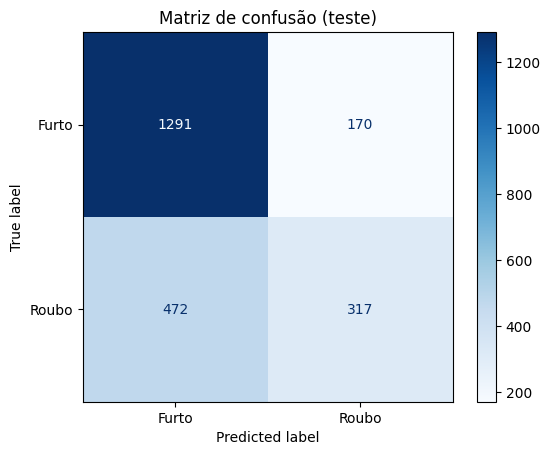

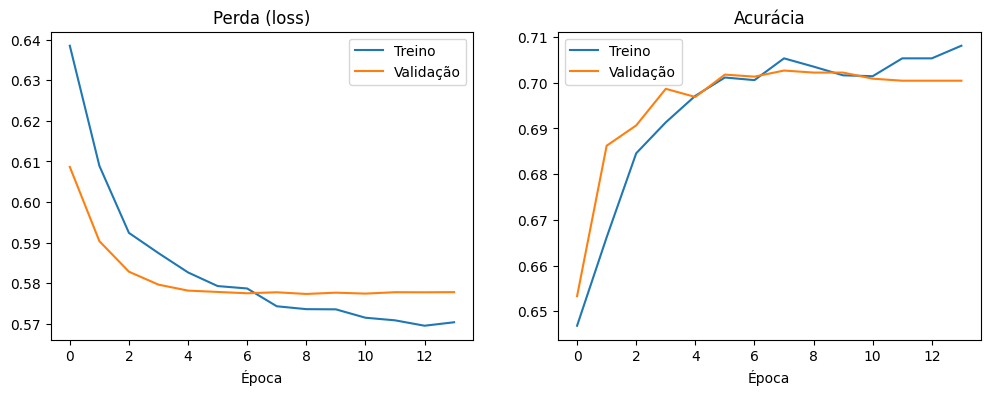

In [15]:
# Modelo escolhido (pra trocar, mudar só estas duas linhas)
melhor = mlp2
hist = hist2

# --- Métricas no TESTE ---
metricas_teste = avaliar(melhor, X_test_enc, y_test)
print("MLP 2 (teste):", {k: round(v, 3) for k, v in metricas_teste.items()})

# --- Matriz de confusão ---
prob = melhor.predict(X_test_enc, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["Furto", "Roubo"]).plot(cmap="Blues")
plt.title("Matriz de confusão (teste)")
plt.show()

# --- Curvas de treino x validação ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(hist.history["loss"], label="Treino")
ax[0].plot(hist.history["val_loss"], label="Validação")
ax[0].set_title("Perda (loss)")
ax[0].set_xlabel("Época")
ax[0].legend()
print()

ax[1].plot(hist.history["accuracy"], label="Treino")
ax[1].plot(hist.history["val_accuracy"], label="Validação")
ax[1].set_title("Acurácia")
ax[1].set_xlabel("Época")
ax[1].legend()

plt.show()

# --- Salvar o modelo ---
melhor.save("modelo_mlp.keras")

### 📝 Avaliação final (MLP 2, conjunto de teste)

| Acurácia | Precision | Recall | F1 |
|---|---|---|---|
| 0,715 | 0,651 | 0,402 | 0,497 |

**Matriz de confusão (2.250 registros de teste):**
- 1.291 furtos classificados corretamente e 170 furtos classificados como roubo
- 317 roubos classificados corretamente e 472 roubos classificados como furto

**Overfitting / underfitting:**
- As curvas de treino e validação ficam muito próximas, e a loss de validação estabiliza em ≈ 0,577. **Não há overfitting.**
- O resultado no teste (acurácia 0,715) é parecido com o da validação (0,702), então o modelo generaliza e não foi ajustado demais à validação.
- A acurácia fica perto de 71%, sinal de uma **limitação de informação** (só 4 atributos gerais), e não de excesso de ajuste.

**Interpretação:** o modelo é mais confiável quando diz "roubo" (precision 0,65), mas deixa escapar mais da metade dos roubos (recall 0,40). Os atributos usados (bairro, dia, período e tipo de local) descrevem *onde e quando*, mas não *como* o crime aconteceu, que é o que mais diferencia roubo de furto.

## 12. Exportando as categorias para o app web

O formulário do app precisa oferecer exatamente as opções que o encoder aprendeu no treino. Aqui salvamos essas categorias em `categorias.json`, junto com o modelo (`modelo_mlp.keras`) e o encoder (`encoder.pkl`), que serão usados na aplicação.

In [16]:
import json

# Pega do encoder todas as categorias que ele aprendeu, por atributo
categorias = {}
for coluna, valores in zip(encoder.feature_names_in_, encoder.categories_):
    categorias[coluna] = [str(v) for v in valores]
    print(f"{coluna}: {len(valores)} opções")

# Salva num arquivo pra Pessoa B usar no formulário
with open("categorias.json", "w", encoding="utf-8") as f:
    json.dump(categorias, f, ensure_ascii=False, indent=2)

BAIRRO_GRUPO: 101 opções
DIA_SEMANA: 7 opções
PERIODO: 4 opções
TIPO_LOCAL: 6 opções
